# 03 · Referencias y candidatos

Reconstruye las tablas de seis candidatos supervisados y sus referencias a partir de las cinco validaciones registradas. No reenvía el experimento GPT ni vuelve a entrenar.

**Alcance de validación.** 2014J ya se había observado en una versión anterior. **No es una prueba final independiente ni un hold-out de un solo uso.** Separar personas y ajustar transformaciones dentro de cada fold evita fugas directas, pero no elimina el conocimiento previo de sus resultados. Las cifras sobre 2014J describen este histórico; la decisión institucional necesita una cohorte futura sin consultar, con protocolo fijado antes de conocer resultados.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p/'src/notebooks.py').is_file()), None)
if ROOT is None and (here/'proyecto_final/src/notebooks.py').is_file():
    ROOT = here/'proyecto_final'
assert ROOT is not None, 'Abrir desde proyecto_final o notebooks.'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT/'.local/matplotlib')
os.environ['PSET4_MODEL_MODE'] = 'fixture'
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.notebooks import evidencia
from src.datos import sha256
E = evidencia()
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
%matplotlib inline
print('Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.')


Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.


## Distinguir las referencias

El predictor estático es la comparación de negocio: usa los mismos cupos sin actividad digital. Dummy es una referencia técnica ingenua. No actuar y asignar apoyo después de conocer Fail tienen otro propósito y horizonte.

,familia,AP_CV,AP_DE,cobertura_CV,cobertura_DE,AP_entrenamiento_muestra,brecha_AP,run_id
0,dummy,0.301150,0.011685,0.091542,0.015024,0.301200,0.000050,dcb91965644a479baa7a0f08555df32e
1,lineal,0.568740,0.024483,0.229226,0.008012,0.584077,0.015337,7f75bbbab6ed4f56b58caa0850529b34
2,bagging,0.561059,0.030092,0.225686,0.011184,1.000000,0.438941,5a936638bef24491932483e0c0ede0df
3,boosting,0.577654,0.027252,0.228074,0.008209,0.726866,0.149212,61ef18564a504ec4bc39e454cbe1f8e9
4,red_neuronal,0.504241,0.028346,0.200911,0.012721,0.777387,0.273146,7ce1fba214954655bf54f7d8e9a83842
5,bayes,0.537542,0.027301,0.227818,0.010680,0.543219,0.005677,dccc18435ccf489794cadd3ce4903342
6,llm_generativo,0.382111,0.039352,0.148656,0.018812,0.392501,0.010389,f4e06d2464e44b1da84b5c7f2ecf55b5


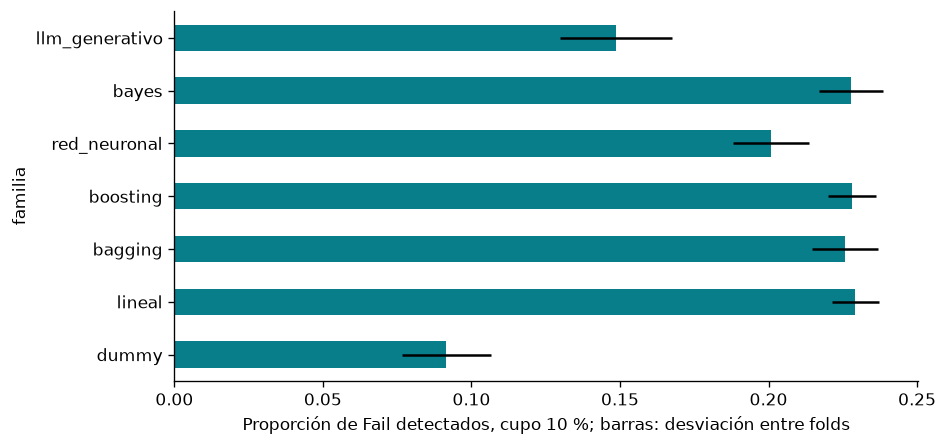

In [2]:
models=E['modelos']; assert models['status']=='complete'
rows=[]
for result in [models['baselines'][0],*models['candidates']]:
    folds=result['folds']; assert len(folds)==5
    for column,fold_column in [('cv_ap_fail_mean','cv_ap_fail'),('cv_coverage_mean','cv_coverage')]:
        np.testing.assert_allclose(result[column], np.mean([f[fold_column] for f in folds]))
    rows.append({'familia':result['family'],'AP_CV':result['cv_ap_fail_mean'],'AP_DE':result['cv_ap_fail_std'],'cobertura_CV':result['cv_coverage_mean'],'cobertura_DE':result['cv_coverage_std'],'AP_entrenamiento_muestra':result['train_ap_fail_mean'],'brecha_AP':result['ap_gap'],'run_id':result['run_id']})
table=pd.DataFrame(rows); display(table)
assert len(models['candidates'])==6
ax=table.plot.barh(x='familia',y='cobertura_CV',xerr='cobertura_DE',figsize=(8,4),legend=False,color='#087e8b')
ax.set_xlabel('Proporción de Fail detectados, cupo 10 %; barras: desviación entre folds'); plt.show()


## Lectura de negocio y uso del LLM

La cobertura responde cuántas matrículas que terminan en Fail caben en la lista financiable. AP resume la calidad del orden de riesgo; no representa un porcentaje de estudiantes atendidos. Las barras de dispersión no son intervalos de confianza independientes.

In [3]:
llm=next(r for r in models['candidates'] if r['family']=='llm_generativo')
assert len(llm['folds'])==5
print('Cobertura GPT:',f"{100*llm['cv_coverage_mean']:.2f}%")
print('Costo registrado de estas validaciones USD:',llm['api_cost_folds_including_prior_checkpoints_usd'])
print('Prompting: 18 ejemplos del entrenamiento de cada fold, seis por clase; validación completa común.')
print('No hubo fine-tuning de pesos. La API externa requiere evaluación posterior de costo-beneficio, privacidad y latencia.')
display(pd.DataFrame([{'familia':r['family'],'ajuste_seg':r['cv_fit_seconds_total'],'inferencia_seg':r['cv_inference_seconds_total'],'costo_nuevas_llamadas_USD':r['api_cost_new_calls_usd']} for r in models['candidates']]))


Cobertura GPT: 14.87%
Costo registrado de estas validaciones USD: 0.85353485
Prompting: 18 ejemplos del entrenamiento de cada fold, seis por clase; validación completa común.
No hubo fine-tuning de pesos. La API externa requiere evaluación posterior de costo-beneficio, privacidad y latencia.


,familia,ajuste_seg,inferencia_seg,costo_nuevas_llamadas_USD
0,lineal,2.757541,0.432196,0.000000
1,bagging,15.632964,0.526103,0.000000
2,boosting,5.160584,0.217157,0.000000
3,red_neuronal,328.081107,0.221983,0.000000
4,bayes,0.876588,0.183671,0.000000
5,llm_generativo,1.157747,349.805297,0.620597


## Lectura final

Los resultados reproducidos pertenecen a los experimentos registrados. La fecha de ejecución de este notebook no los convierte en evidencia nueva de generalización. Consulte `README.md` para insumos, dependencias y comandos del pipeline completo.